# Figure 6: Deep-learning packages and workflows

Reproduce all four panels on deep-learning package mentions, vocabulary fractions, host-platform co-mentions and workflow categories. The notebook uses committed counts and agreed labels from three samples per method. It checks aggregate fractions and intervals without opening article text.

## Inputs

| Committed file | Contents | Producer |
| --- | --- | --- |
| `config/tools.yml` | Curated aliases, categories and query context | Manual registry, read by `python -m census.build.build_dataset` |
| `data/processed/tools.csv` | Package names, categories, scope and aggregate flags | `python -m census.build.build_dataset` |
| `data/processed/literature_yearly.csv` | Yearly package mention counts by source | `python -m census.build.build_dataset` |
| `data/processed/dl_estimates.csv` | Deep-learning vocabulary counts, sample sizes and intervals | `python -m census.build.build_dataset` |
| `data/processed/dl_split_yearly.csv` | Yearly vocabulary-based deep-learning and other estimated counts | `python -m census.build.build_dataset` |
| `data/processed/dl_host_comentions.csv` | Cellpose and StarDist co-mention counts for host platforms | `python -m census.build.build_hosts` |
| `data/processed/cellpose_workflow_pooled_2025.csv` | Pooled agreed Cellpose workflow labels across three samples | `python -m census.validation.label_round2 pooled` |
| `data/processed/stardist_workflow_2025_pooled.csv` | Pooled agreed StarDist workflow labels across three samples | `python -m census.validation.workflow_hosts pooled` |
| `data/processed/ilastik_workflow_2025_pooled.csv` | Pooled agreed ilastik workflow labels across three samples | `python -m census.validation.workflow_hosts pooled` |
| `config/dl_lexicon.yml` | Vocabulary rules, guards and lexicon version | Manual lexicon, read by `python -m census.build.build_dataset` |

Input paths are relative to the repository root. The closing check also reads `../MANUSCRIPT/FIGURES/Figure6__deep_learning.png` when present. The manuscript image is optional and stays outside a public clone.

## Set up offline analysis

Locate the repository in either layout, load the package registry and import the shared publication renderer. This cell makes no API requests.

In [1]:
from pathlib import Path
from io import BytesIO
from tempfile import TemporaryDirectory
import sys
import hashlib

import numpy as np
import pandas as pd
from IPython.display import Image, display
from PIL import Image as PILImage
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
SCRIPTS_DIR = next(p for p in (cwd, *cwd.parents) if (p / 'census' / '_registry.py').is_file())
REPO_ROOT = SCRIPTS_DIR.parent
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

from census._registry import build_boolean_query, load_registry
from census.figures import fig6_deep_learning as figure
from census.figures import style as fs

reg = load_registry()
def inspect_processed(name, columns=None):
    frame = fs.load(name)
    print(f'{name}: shape={frame.shape}')
    display((frame if columns is None else frame[columns]).head())
    return frame


## Registry and query construction

The same registry aliases and microscopy context define package counts and the full-text microscopy denominator. `_registry.build_boolean_query()` makes the alias clause explicit. The four mentioned deep-learning packages are Cellpose, StarDist, deepImageJ, and ZeroCostDL4Mic.

In [2]:
registry_table = pd.DataFrame([
    {'tool_id': tool.id, 'name': tool.name, 'category': tool.category, 'scope': tool.scope,
     'in_aggregate': tool.in_aggregate, 'aliases': ' | '.join(tool.aliases),
     'query': build_boolean_query(tool, reg.context_query)}
    for tool in reg.tools
])
print(f'{len(reg.tools)} packages; years {reg.year_start}-{reg.year_end}')
print(f'Shared context: {reg.context_query}')
print(f'Registry table shape: {registry_table.shape}')
display(registry_table.drop(columns='query').head(8))
display(registry_table.loc[registry_table.tool_id.isin(['cellpose', 'stardist', 'imagej']), ['tool_id', 'aliases', 'query']])

30 packages; years 2010-2025
Shared context: (microscopy OR microscope) AND HAS_FT:Y
Registry table shape: (30, 7)


,tool_id,name,category,scope,in_aggregate,aliases
0,jupyter,Jupyter notebooks,notebook,core,False,Jupyter | Jupyter notebook | IPython notebook
1,imagej,ImageJ / Fiji,general-platform,core,True,ImageJ | ImageJ2 | Fiji | FIJI
2,napari,napari,general-platform,core,True,napari
3,cellprofiler,CellProfiler,general-platform,core,True,CellProfiler
4,qupath,QuPath,general-platform,core,True,QuPath
5,icy,Icy,general-platform,core,True,Icy bioimage | Icy software | de Chaumont Icy
6,ilastik,ilastik,general-platform,core,True,ilastik
7,knime,KNIME,general-platform,core,True,KNIME


,tool_id,aliases,query
1,imagej,ImageJ | ImageJ2 | Fiji | FIJI,"(""ImageJ2"" OR ""ImageJ"" OR ""Fiji"" OR ""FIJI"") AN..."
8,cellpose,Cellpose,"""Cellpose"" AND ((microscopy OR microscope) AND..."
9,stardist,StarDist,"""StarDist"" AND ((microscopy OR microscope) AND..."


## Read panel inputs

Load the committed data for the calculations below. Panels a-d show deep-learning method mentions, vocabulary fractions, host co-mentions and agreed workflow labels. We reconstruct fractions and intervals from aggregate counts and check pooled workflow totals.

In [3]:
estimates = inspect_processed('dl_estimates.csv')
splits = inspect_processed('dl_split_yearly.csv')
hosts = inspect_processed('dl_host_comentions.csv')
from census.build import classify_dl
pooled_files = {'cellpose': 'cellpose_workflow_pooled_2025.csv',
                'stardist': 'stardist_workflow_2025_pooled.csv',
                'ilastik': 'ilastik_workflow_2025_pooled.csv'}
pooled_tables = {method: inspect_processed(name, ['category', 'pooled']) for method, name in pooled_files.items()}


dl_estimates.csv: shape=(480, 10)


,tool_id,year,population,n_sampled,n_dl,dl_fraction,ci_lo,ci_hi,sampling,lexicon_version
0,jupyter,2010,0,0,0,0.0,0.0,0.0,census,2
1,jupyter,2011,0,0,0,0.0,0.0,0.0,census,2
2,jupyter,2012,0,0,0,0.0,0.0,0.0,census,2
3,jupyter,2013,2,2,0,0.0,0.0,0.0,census,2
4,jupyter,2014,0,0,0,0.0,0.0,0.0,census,2


dl_split_yearly.csv: shape=(480, 6)


,tool_id,year,base_count,dl_fraction,count_dl,count_nondl
0,jupyter,2010,0,0.0,0,0
1,jupyter,2011,0,0.0,0,0
2,jupyter,2012,0,0.0,0,0
3,jupyter,2013,2,0.0,0,2
4,jupyter,2014,0,0.0,0,0


dl_host_comentions.csv: shape=(36, 10)


...

,category,pooled
0,separate,68
1,inside_fiji,5
2,other_pipeline,10
3,unclear,12
4,mention_only,13


stardist_workflow_2025_pooled.csv: shape=(7, 5)


,category,pooled
0,separate,19
1,inside_fiji,51
2,other_pipeline,15
3,unclear,14
4,mention_only,10


ilastik_workflow_2025_pooled.csv: shape=(7, 5)


,category,pooled
0,separate,67
1,inside_fiji,2
2,other_pipeline,2
3,unclear,14
4,mention_only,20


## Reconstruct panel quantities

Panels a-d show deep-learning method mentions, vocabulary fractions, host co-mentions and agreed workflow labels. We reconstruct fractions and intervals from aggregate counts and check pooled workflow totals.

In [4]:
estimate_2025 = estimates.loc[estimates.year.eq(2025)].set_index('tool_id')
classification = []
for package in ['imagej', 'imaris', 'cellpose', 'stardist']:
    row = estimate_2025.loc[package]
    n_dl, n = int(row.n_dl), int(row.n_sampled)
    fraction = n_dl / n
    lo, hi = (fraction, fraction) if row.sampling == 'census' else classify_dl.wilson(n_dl, n)
    assert round(fraction, 4) == row.dl_fraction
    np.testing.assert_allclose([round(lo, 4), round(hi, 4)], [row.ci_lo, row.ci_hi])
    classification.append({'package': package, 'n_dl': n_dl, 'n_sampled': n,
                           'share_percent': 100 * fraction, 'sampling': row.sampling})
print(f'Lexicon version: {classify_dl.lexicon_version()}')
display(pd.DataFrame(classification))
counts_2025 = fs.europepmc_yearly().query('year == 2025').set_index('tool_id')['count']
named = fs.named_dl_share().sum(axis=1) * 10
tracked = counts_2025.loc[['cellpose', 'stardist', 'deepimagej', 'zerocostdl4mic']].sum()
share_two = 100 * counts_2025.loc[['cellpose', 'stardist']].sum() / tracked
print(f'Named deep-learning packages per 1,000 core-package matches: {named.loc[2020]:.1f} in 2020, {named.loc[2025]:.1f} in 2025.')
print(f'Cellpose and StarDist share of the four named deep-learning packages in 2025: {share_two:.1f}%.')

host_2025 = hosts.loc[hosts.year.eq(2025), ['dl_tool', 'host', 'n_dl', 'n_with_host', 'share_host']]
display(host_2025)
# Panel d: how each method was run in papers that also mention ImageJ/Fiji, agreed labels pooled.
# ilastik is a machine-learning package included for comparison; its Fiji plugin applies projects
# trained in the ilastik application, so its standalone category covers nearly all its workflows.
categories = [key for key, _, _ in figure.WORKFLOW]
panel_d = {}
for method, name in pooled_files.items():
    counts = pooled_tables[method].set_index('category')
    agreed = counts.loc[categories, 'pooled']
    assert agreed.sum() == int(counts.loc['agreed', 'pooled']), method
    assert (counts.loc[categories, ['r1', 'r2', 'r3']].sum(axis=1) == agreed).all(), method
    assert int(counts.loc['labelled', 'pooled']) == 120, method
    panel_d[method] = 100 * agreed / agreed.sum()
display(pd.DataFrame(panel_d).T.round(1))
agreed = {method: int(tables.set_index('category').loc['agreed', 'pooled']) for method, tables in pooled_tables.items()}
print('Agreed papers: ' + ', '.join(f'{m} {n}' for m, n in agreed.items()))


Lexicon version: 2


,package,n_dl,n_sampled,share_percent,sampling
0,imagej,4,1000,0.400000,simple-random
1,imaris,20,1000,2.000000,simple-random
2,cellpose,107,778,13.753213,census
3,stardist,55,356,15.449438,census


Named deep-learning packages per 1,000 core-package matches: 0.8 in 2020, 20.5 in 2025.
Cellpose and StarDist share of the four named deep-learning packages in 2025: 97.6%.


,dl_tool,host,n_dl,n_with_host,share_host
15,cellpose,imagej,778,515,0.6620
16,cellpose,qupath,778,86,0.1105
17,cellpose,napari,778,90,0.1157
33,stardist,imagej,356,246,0.6910
34,stardist,qupath,356,103,0.2893
35,stardist,napari,356,41,0.1152


category,separate,inside_fiji,other_pipeline,unclear,mention_only
cellpose,63.0,4.6,9.3,11.1,12.0
stardist,17.4,46.8,13.8,12.8,9.2
ilastik,63.8,1.9,1.9,13.3,19.0


Agreed papers: cellpose 108, stardist 109, ilastik 105


## Rebuilding from scratch

All default cells run offline from the committed inputs above. Source collectors need network access when their raw API caches are absent. `python -m census.build.build_dataset` collects counts and snapshots, the specialised producer modules listed under Inputs rebuild their own derived tables. Snapshots retain their original collection date.

To restore sampled titles and abstracts, run `python release/refetch_identifiers.py` with network access. The refetched corpus supports vocabulary classification and research-area calculations. A public clone omits that corpus and the raw response caches. These notebooks display derived data and never fetch records during execution.

`python -m census.build.build_dataset` applies the versioned lexicon to the corpus. This notebook checks stored `n_dl` and `n_sampled` counts and Wilson intervals offline. Reclassifying individual records needs the refetched corpus.

## Render all panels

Build `Figure6__deep_learning` with the shared 300 dpi publication style. Save PNG, PDF and SVG in a temporary directory and retain the full-size PNG pixels for the closing check. Display a scaled preview.

wrote Figure6__deep_learning.png/.pdf/.svg
Figure6__deep_learning: 2189 x 1609 pixels


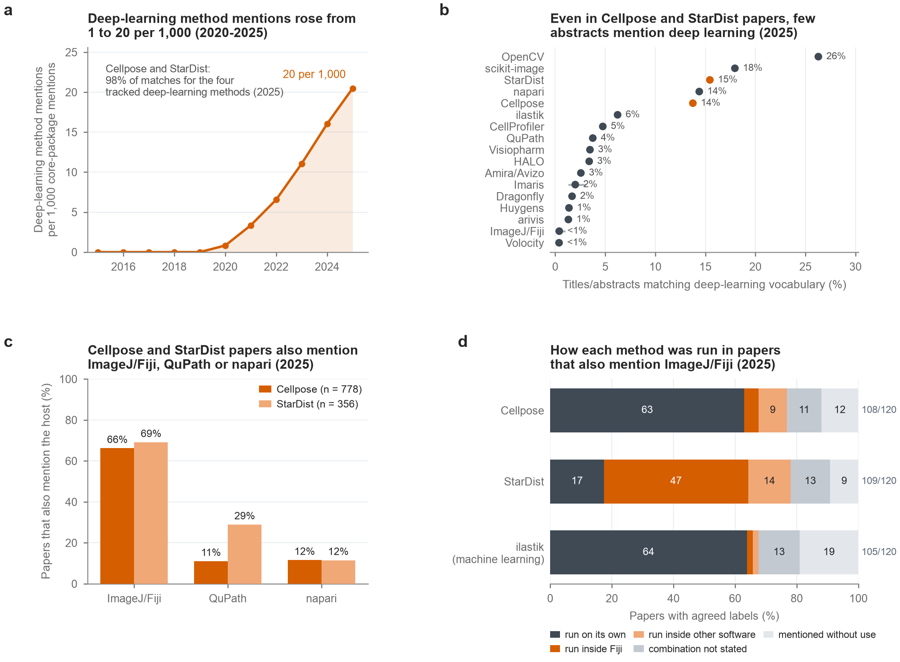

In [5]:
OUTPUT_STEM = 'Figure6__deep_learning'
fig = figure.build_figure()
with TemporaryDirectory(prefix='notebook-render-') as output_dir:
    fs.save(fig, OUTPUT_STEM, out_dir=output_dir)
    png_bytes = (Path(output_dir) / (OUTPUT_STEM + '.png')).read_bytes()
rendered_pixels = np.asarray(PILImage.open(BytesIO(png_bytes)).convert('RGBA'))
print(f'{OUTPUT_STEM}: {rendered_pixels.shape[1]} x {rendered_pixels.shape[0]} pixels')
preview = PILImage.open(BytesIO(png_bytes))
preview.thumbnail((900, 900))
preview_bytes = BytesIO()
preview.save(preview_bytes, format='PNG')
display(Image(data=preview_bytes.getvalue(), width=min(640, preview.width)))
plt.close('all')


## Check against the manuscript

Assert exact pixel equality, including image dimensions and every panel, when the manuscript PNG exists. A public clone prints a skip note for that comparison and still checks that rendering produced pixels. The pixel hash supports comparisons across runs.

In [6]:
assert rendered_pixels.size > 0
reference = REPO_ROOT / 'MANUSCRIPT' / 'FIGURES' / (OUTPUT_STEM + '.png')
if reference.is_file():
    expected_pixels = np.asarray(PILImage.open(reference).convert('RGBA'))
    assert rendered_pixels.shape == expected_pixels.shape, 'Manuscript image dimensions differ'
    np.testing.assert_array_equal(rendered_pixels, expected_pixels)
    print(f'{OUTPUT_STEM}: identical to manuscript PNG (all pixels, all panels)')
else:
    print(f'{OUTPUT_STEM}: manuscript comparison skipped; manuscript PNG is absent in this clone')
print('Rendered pixel SHA-256:', hashlib.sha256(rendered_pixels.tobytes()).hexdigest())


Figure6__deep_learning: identical to manuscript PNG (all pixels, all panels)
Rendered pixel SHA-256: 84754d188c4c9c33771e9510db9fad3c87ed768171ad0363f55f3ff2ff8d115e
